---
title: "The Wave Function — Level 2"
short_title: "01 The Wave Function"
numbering:
  heading_2: true
  equation: true
---

# The Wave Function

:::{seealso} Math for this topic
- [Q-M1: Complex functions, probability and wave packets](../math/01-complex-probability.ipynb)
- [T-M2: Gaussian, Gamma and quantum-statistics integrals](../../level2-thermo-book/math/02-gaussian-gamma-integrals.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 34 | de Broglie wavelength, photon energy, uncertainty estimates |
| **2** | **Griffiths QM, ch. 1** | **Statistical interpretation, normalization, expectation values, momentum space** |
| 3 | Sakurai, ch. 1 | Kets, bras, Hilbert space, measurement and observables |

The new skill at this level: treating the wave function as a probability amplitude you can normalize, average over, and evolve with the Schrödinger equation

Math for this topic: Q-M1 (complex functions, probability, Fourier transforms) and thermo T-M2 (Gaussian integrals).
:::

Workbook example ladder: the wavelength of an electron → normalizing ψ and computing ⟨x⟩ and ⟨p⟩ → rewriting the state in abstract ket notation. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Waves of What?

Electrons fired one at a time through two slits land at single points on a screen, like particles. But after thousands have landed, the points form an interference pattern, like waves. Neither picture alone fits. Quantum mechanics keeps both: a particle is described by a complex **wave function** $\Psi(x, t)$ that spreads and interferes like a wave, and a measurement finds the particle at one place with a probability set by $|\Psi|^2$.

**de Broglie's relation** ties the wave to the particle's momentum:

$$
\lambda = \frac hp,\qquad p = \hbar k .
$$ (eq-de-broglie)

::::{prf:example} Level 1 rung: the wavelength of an electron
:label: ex-electron-wavelength

An electron is accelerated through 100 V. Find its de Broglie wavelength.

:::{dropdown} Solution
Its kinetic energy is 100 eV, so $p = \sqrt{2mK} = \sqrt{2(9.11\times10^{-31})(1.60\times10^{-17})} = 5.40\times10^{-24}$ kg·m/s and $\lambda = h/p = 0.123$ nm, about the spacing of atoms in a crystal. That is why crystals diffract electrons (Davisson and Germer, 1927).
:::
::::

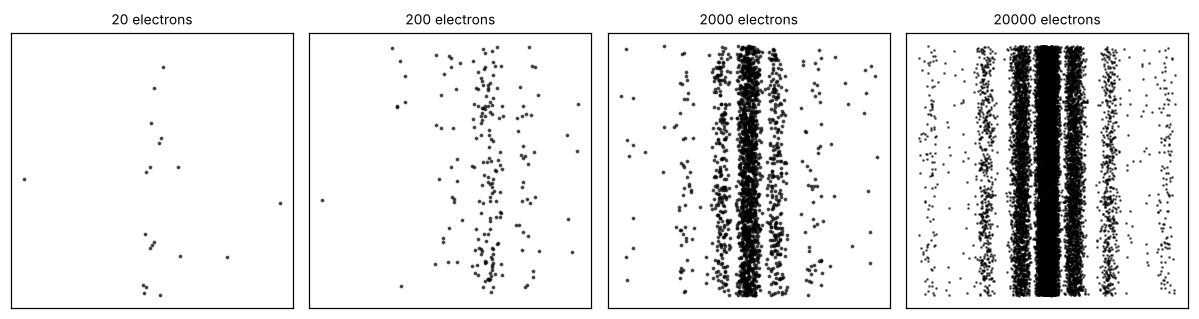

In [2]:
#| label: fig-two-slit-buildup
#| caption: "Simulated two-slit pattern built from single detections. Each dot is one electron landing at a position drawn at random from |Ψ|² (a two-slit interference pattern under a single-slit envelope). With 20 detections the pattern is invisible; with 20 000 it is unmistakable. The wave function predicts only the distribution."
rng = np.random.default_rng(7)
xs = np.linspace(-1, 1, 2000)
I = np.cos(14 * xs)**2 * np.sinc(3 * xs)**2
cdf = np.cumsum(I); cdf /= cdf[-1]
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for ax, N in zip(axes, [20, 200, 2000, 20000]):
    hits = np.interp(rng.random(N), cdf, xs)
    ax.plot(hits, rng.random(N), ".", ms=1.5 if N > 2000 else 3, color="k", alpha=0.6)
    ax.set_title(f"{N} electrons", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## The Schrödinger Equation

The wave function of a particle of mass $m$ in a potential $V(x)$ evolves by

$$
i\hbar\frac{\partial\Psi}{\partial t} = -\frac{\hbar^2}{2m}\frac{\partial^2\Psi}{\partial x^2} + V(x)\Psi .
$$ (eq-schrodinger)

It plays the role of Newton's second law: given $\Psi(x, 0)$, it determines $\Psi(x, t)$. It is first order in time (so $\Psi$ at one instant is the complete state), linear (so superpositions of solutions are solutions, the source of interference), and has an explicit $i$ (so solutions are necessarily complex).

## The Statistical Interpretation

:::{prf:definition} Born rule
:label: def-born-rule

$|\Psi(x, t)|^2\,dx$ is the probability of finding the particle between $x$ and $x + dx$ at time $t$, if you measure its position then.
:::

So $|\Psi|^2$ is a probability density (Q-M1) and must integrate to 1:

$$
\int_{-\infty}^{\infty}|\Psi(x, t)|^2\,dx = 1 .
$$ (eq-normalization)

Two consequences are worth stating plainly:

- **Indeterminacy.** Even with complete knowledge of $\Psi$, you can predict only probabilities. The orthodox (Copenhagen) view is that the particle had no definite position before the measurement.
- **Collapse.** Measure the position and find $x_0$; measure again immediately and you get $x_0$ again. So the measurement changes the wave function, which collapses to a spike at $x_0$ and then spreads according to {eq}`eq-schrodinger`.

### Normalization is preserved

If $\Psi$ is normalized at $t = 0$, is it still normalized later? It must be, or the interpretation would fail. Using {eq}`eq-schrodinger` and its complex conjugate,

$$
\frac{\partial|\Psi|^2}{\partial t} = -\frac{\partial J}{\partial x},\qquad
J = \frac{\hbar}{2mi}\left(\Psi^*\frac{\partial\Psi}{\partial x} - \Psi\frac{\partial\Psi^*}{\partial x}\right) ,
$$ (eq-probability-current)

a continuity equation, like charge conservation in E&M. Integrating over all $x$, the right side gives $J(\infty) - J(-\infty) = 0$ for a normalizable state. Probability flows but is never created or destroyed. $J$ is the **probability current**.

In [3]:
# Probability current of a plane wave and of a real wave function
x, t, k, A = sp.symbols("x t k A", real=True)
m, hb = sp.symbols("m hbar", positive=True)
def current(psi):
    return sp.simplify(hb / (2 * m * sp.I) * (sp.conjugate(psi) * sp.diff(psi, x) - psi * sp.diff(sp.conjugate(psi), x)))
display(Math(r"\Psi = Ae^{ikx}:\quad J = " + sp.latex(current(A * sp.exp(sp.I * k * x)))))
display(Math(r"\Psi = A\cos kx:\quad J = " + sp.latex(current(A * sp.cos(k * x)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

A plane wave carries current $|A|^2\hbar k/m$: density times velocity. A standing wave (real up to a phase) carries none.

## Expectation Values

The **expectation value** of $x$ is the average of many position measurements on identically prepared particles:

$$
\langle x\rangle = \int x\,|\Psi|^2\,dx .
$$

For momentum, take the time derivative of $\langle x\rangle$, use {eq}`eq-schrodinger`, and integrate by parts twice. The result is $m\,d\langle x\rangle/dt = \int\Psi^*(-i\hbar\,\partial_x)\Psi\,dx$, which identifies the momentum **operator**:

$$
\langle p\rangle = \int\Psi^*\left(-i\hbar\frac{\partial}{\partial x}\right)\Psi\,dx ,
\qquad
\langle Q(x, p)\rangle = \int\Psi^*\,Q\!\left(x, -i\hbar\frac{\partial}{\partial x}\right)\Psi\,dx .
$$ (eq-expectation-operators)

To compute the average of any dynamical quantity, replace $p$ by $-i\hbar\,\partial/\partial x$ and sandwich between $\Psi^*$ and $\Psi$. Kinetic energy is $\langle T\rangle = -\frac{\hbar^2}{2m}\int\Psi^*\Psi''\,dx$.

**Ehrenfest's theorem.** Expectation values obey classical-looking laws:

$$
\frac{d\langle x\rangle}{dt} = \frac{\langle p\rangle}{m},\qquad \frac{d\langle p\rangle}{dt} = \left\langle-\frac{\partial V}{\partial x}\right\rangle .
$$ (eq-ehrenfest)

(Note: $\langle-V'(x)\rangle$, not $-V'(\langle x\rangle)$. The two agree only if $V$ is at most quadratic, or the packet is narrow.)

::::{prf:example} Level 2 rung: a parabolic wave function
:label: ex-parabolic-psi

At $t = 0$ a particle in $0\le x\le a$ has $\Psi(x, 0) = Ax(a - x)$ (and zero outside). Normalize it and find $\langle x\rangle$, $\langle p\rangle$, $\sigma_x$, $\sigma_p$.

:::{dropdown} Solution
$\int_0^ax^2(a - x)^2dx = a^5/30$, so $A = \sqrt{30/a^5}$. By symmetry $\langle x\rangle = a/2$, and since $\Psi$ is real, $\langle p\rangle = 0$ (Q-M1). The SymPy cell below does the rest: $\sigma_x = a/\sqrt{28}\approx0.189a$, $\sigma_p = \sqrt{10}\,\hbar/a$, and $\sigma_x\sigma_p = \sqrt{10/28}\,\hbar = 0.598\hbar$, comfortably above $\hbar/2$.
:::
::::

In [4]:
a = sp.symbols("a", positive=True)
xx = sp.symbols("x", real=True)
psi = sp.sqrt(30 / a**5) * xx * (a - xx)
ev = lambda f: sp.simplify(sp.integrate(f, (xx, 0, a)))
norm = ev(psi**2)
xm, x2 = ev(xx * psi**2), ev(xx**2 * psi**2)
pm = ev(psi * (-sp.I * hb) * sp.diff(psi, xx))
p2 = ev(psi * (-hb**2) * sp.diff(psi, xx, 2))
sx, sp_ = sp.sqrt(sp.simplify(x2 - xm**2)), sp.sqrt(p2 - pm**2)
display(Math(r"\int|\Psi|^2 = " + sp.latex(norm) + r",\ \langle x\rangle = " + sp.latex(xm) + r",\ \langle p\rangle = " + sp.latex(pm)))
display(Math(r"\sigma_x = " + sp.latex(sx) + r",\ \sigma_p = " + sp.latex(sp_) + r",\ \sigma_x\sigma_p = " + sp.latex(sp.simplify(sx * sp_)) + rf"\approx {float(sp.sqrt(sp.Rational(10, 28))):.3f}\,\hbar"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

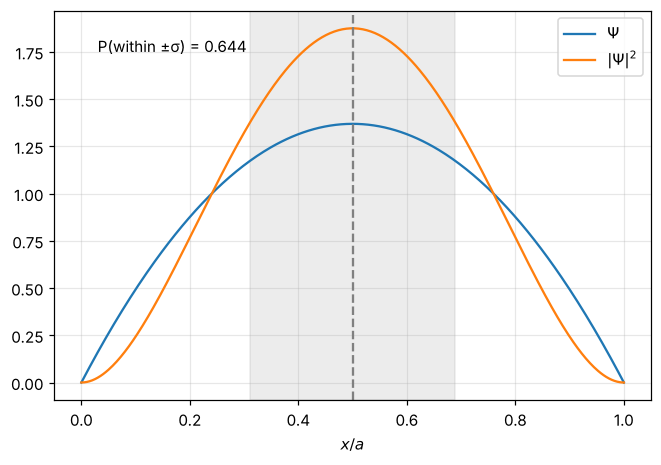

In [5]:
#| label: fig-parabolic-psi
#| caption: "The parabolic state Ψ = √(30/a⁵) x(a − x) (blue) and its probability density (orange), with ⟨x⟩ (dashed) and ⟨x⟩ ± σ_x (shaded). About 64% of the probability lies within one standard deviation, a bit less than a Gaussian's 68%."
X = np.linspace(0, 1, 400); ps = np.sqrt(30) * X * (1 - X); s_ = 1 / np.sqrt(28)
fig, ax = plt.subplots()
ax.plot(X, ps, label="$\\Psi$"); ax.plot(X, ps**2, label="$|\\Psi|^2$")
ax.axvline(0.5, ls="--", color="gray"); ax.axvspan(0.5 - s_, 0.5 + s_, color="gray", alpha=0.15)
inside = quad(lambda x: 30 * x**2 * (1 - x)**2, 0.5 - s_, 0.5 + s_)[0]
ax.text(0.03, 1.75, f"P(within ±σ) = {inside:.3f}")
ax.set_xlabel("$x/a$"); ax.legend(); plt.show()

## The Uncertainty Principle

For any state,

$$
\sigma_x\sigma_p\ge\frac\hbar2 .
$$ (eq-heisenberg)

It is not about clumsy measurements; it is a property of waves. A wave function sharply peaked in $x$ is built from many wavelengths (Q-M1's Fourier pair), so its momentum is spread out, and vice versa. Quantum topic 4 proves {eq}`eq-heisenberg` from the commutator $[\hat x, \hat p] = i\hbar$ and generalizes it to any pair of observables. The Gaussian is the only shape that achieves equality.

## Momentum Space

The momentum-space wave function is the Fourier transform (Q-M1, {eq}`eq-momentum-space`), and $|\Phi(p, t)|^2\,dp$ is the probability of finding momentum in $[p, p + dp]$. $\Psi(x)$ and $\Phi(p)$ describe the same state in two representations, and Level 3 makes that literal: the state is an abstract ket $|\mathcal S\rangle$, with $\Psi(x) = \langle x|\mathcal S\rangle$ and $\Phi(p) = \langle p|\mathcal S\rangle$ its components in two bases (Q-M3).

## Exercises

### Exercises

1. Find the de Broglie wavelengths of a 1 eV electron, a thermal neutron (kinetic energy $\tfrac32kT$ at 300 K), and a 0.15 kg baseball at 40 m/s.
2. Normalize $\Psi(x) = Ae^{-\lambda|x|}$ and find $\langle x\rangle$, $\langle x^2\rangle$, and $\sigma_x$. What is the probability of finding the particle beyond $\sigma_x$ from the origin?
3. Show that $\langle p\rangle$ is real for any normalizable $\Psi$. (Integrate by parts.)
4. Derive the continuity equation {eq}`eq-probability-current` from {eq}`eq-schrodinger`.
5. For $\Psi = Ax(a - x)$, find $\langle T\rangle$ (kinetic energy) and compare with the ground-state energy $\pi^2\hbar^2/2ma^2$ of the infinite well (quantum topic 2).

:::{dropdown} Hints
1. $\lambda = h/\sqrt{2mK}$; for the baseball, $\lambda = h/mv$.
2. $\int_0^\infty x^2e^{-2\lambda x}dx = 1/(4\lambda^3)$.
3. Show $\langle p\rangle^* = \langle p\rangle$.
4. Compute $\partial_t(\Psi^*\Psi) = \Psi^*\dot\Psi + \Psi\dot\Psi^*$ and substitute.
5. $\langle T\rangle = \langle p^2\rangle/2m$.
:::

:::{dropdown} Answers
1. Electron: 1.23 nm. Neutron (0.039 eV): 0.146 nm. Baseball: $1.1\times10^{-34}$ m, absurdly small.
2. $A = \sqrt\lambda$; $\langle x\rangle = 0$; $\langle x^2\rangle = 1/2\lambda^2$; $\sigma_x = 1/(\sqrt2\lambda)$; $P(|x| > \sigma) = e^{-\sqrt2} = 0.243$.
3. $\langle p\rangle^* = i\hbar\int\Psi\,\partial_x\Psi^* = -i\hbar\int\Psi^*\partial_x\Psi = \langle p\rangle$ after integrating by parts.
4. The $V$ terms cancel; the second-derivative terms combine into $-\partial_xJ$.
5. $\langle T\rangle = 5\hbar^2/ma^2$, versus $\pi^2\hbar^2/2ma^2 = 4.935\hbar^2/ma^2$: only 1.3% higher, as the variational principle (topic 9) says it must be.
:::

## Summary

- $\lambda = h/p$; matter interferes, but detections are single events distributed as $|\Psi|^2$.
- The Schrödinger equation is first order in time and linear; normalization is preserved because probability obeys a continuity equation.
- Expectation values use operators: $x\to x$, $p\to-i\hbar\,\partial_x$. Ehrenfest: averages obey Newton-like laws.
- $\sigma_x\sigma_p\ge\hbar/2$, a property of waves; $\Phi(p)$ is the same state in momentum space.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.